# Практическое задание № 1. Классификация


**Работу выполнил (а):**

Басиони Абдельсалам Али Абдельсалам, 465144

# Распознавание активности человека на основе данных с мобильных сенсоров

Необходимо по данным с мобильных сенсоров при помощи прикладных алгоритмов машинного обучения предсказать активность человека по шести классам движений:
* Движется по прямой
* Движется вверх (например, движение по лестнице вверх)
* Движется вниз (например, движение по лестнице вниз)
* Сидит
* Стоит
* Лежит

## Сведения о наборе данных
Набор данных содержит записи датчиков со сматфонов (акселерометр и гироскоп с частотой дискретизации 50 Гц) от 30 участников, выполняющих следующие действия: ходьба, ходьба по лестнице, ходьба по лестнице, сидение, стояние и лежание. Данные были предварительно обработаны при помощи фильтров шума. Набор данных представлен Хорхе Л. Рейес-Ортисом.

Признаки были извлечены из 3-х осевых необработанных сигналов акселерометра и гироскопа tAcc-XYZ и tGyro-XYZ. Эти сигналы были сняты с постоянной частотой 50 Гц. Затем были отфильтрованны с помощью медианного фильтра и низкочастотного фильтра Баттерворта 3-го порядка с частотой 20 Гц для удаления шумов. Аналогичным образом сигнал ускорения был разделен на сигналы ускорения тела и гравитации (`tBodyAcc-XYZ` и `tGravityAcc-XYZ`) с помощью другого низкочастотного фильтра Баттерворта с угловой частотой 0,3 Гц. Линейное ускорение тела и угловая скорость были использованы для получения сигналов "рывка" — (`tBodyAccJerk-XYZ` и `tBodyGyroJerk-XYZ`). Также величина этих трехмерных сигналов была расчитана с использованием евклидовой нормы — (`tBodyAccMag`, `tGravityAccMag`, `tBodyAccJerkMag`, `tBodyGyroMag`, `tBodyGyroJerkMag`).

Наконец, к некоторым из этих сигналов было применено быстрое преобразование Фурье (БПФ), в результате чего получились `fBodyAcc-XYZ`, `fBodyAccJerk-XYZ`, `fBodyGyro-XYZ`, `fBodyAccJerkMag`, `fBodyGyroMag`, `fBodyGyroJerkMag`. (Обратите внимание на "f" для обозначения сигналов в частотной области).

Набор переменных, которые были оценены по этим сигналам, следующий:
* mean(): Среднее значение
* std(): Стандартное отклонение
* mad(): Среднее абсолютное отклонение
* max(): Наибольшее значение в массиве
* min(): Наименьшее значение в массиве
* sma(): Область величины сигнала
* energy(): Мера энергии. Сумма квадратов, деленная на количество значений.
* iqr(): Интерквартильный размах
* entropy(): Энтропия сигнала
* arCoeff(): Коэффициенты авторегрессии с порядком Burg, равным 4
* correlation(): коэффициент корреляции между двумя сигналами
* maxInds(): индекс частотной составляющей с наибольшей величиной
* meanFreq(): средневзвешенное значение частотных компонент для получения средней частоты
* skewness(): перекос сигнала в частотной области
* kurtosis(): эксцесс сигнала в частотной области
* bandsEnergy(): Энергия частотного интервала в пределах 64 бинов БПФ каждого окна.
* angle(): Угол между векторами.
## Импорт библиотек
Первым делом импортируем необходимые библиотеки для работы с данными:

In [1]:
# --- Import libraries ---
import os                        # file path handling
import time                      # measuring model training time
import numpy as np               # numerical arrays
import pandas as pd              # tabular data (DataFrame)
import matplotlib.pyplot as plt  # plotting
import seaborn as sns            # color palettes for plots

import warnings
warnings.filterwarnings('ignore')  # hide sklearn service warnings to keep the report clean
RANDOM_STATE = 42                  # fix the random seed for reproducibility

## Считываем набор данных

В прикладных задачах машинного обучения очень важен процесс извлечения признаков (feature extraction), в ходе которого данные интерпретируются в информативные признаки. Также этот процесс может называться проектирование признаков (feature engineering), это весьма трудоемкая и творческая задача. В рамках работы мы опустим эту часть и воспользуемся предобработанными данными.

In [2]:
# Data path: on the course platform the files are in /data/notebook_files,
# when run locally they are in the current folder next to the notebook
DATA_PATH = '/data/notebook_files' if os.path.exists('/data/notebook_files') else '.'

def read_data(path, filename):
    """Reads CSV file `filename` from directory `path` into a DataFrame."""
    return pd.read_csv(os.path.join(path, filename))

df = read_data(DATA_PATH, 'train.csv')
df.head()  # first 5 rows: 561 features + participant id (subject) + activity label (Activity)

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,1,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,1,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,1,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,1,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,1,STANDING


Размер обучающей выборки: (7352, 563)
Пропуски: 0


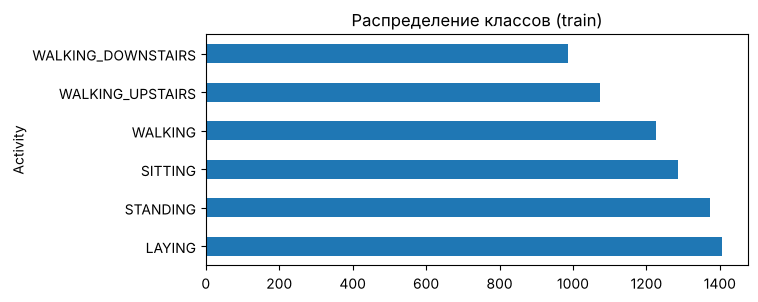

In [3]:
# Brief exploratory analysis: shape, missing values and class balance
print('Размер обучающей выборки:', df.shape)
print('Пропуски:', df.isna().sum().sum())  # total number of missing values in the whole table

# Classes are roughly balanced, so accuracy is a reasonable metric alongside F1
df['Activity'].value_counts().plot(kind='barh', figsize=(7, 3), title='Распределение классов (train)')
plt.show()

Теперь, загрузим полный набор данных и сохранить его под следующими четырьмя переменными:

* `train_X`: признаки, используемые для обучения модели
* `train_y`: метки, используемые для обучения модели
* `test_X`: признаки, используемые для проверки модели
* `test_y`: метки, используемые для проверки модели

In [4]:
def load_dataset(label_dict):
    """Loads the train and test sets and splits them into features X and labels y."""
    train = read_data(DATA_PATH, 'train.csv')
    test = read_data(DATA_PATH, 'test.csv')
    # the last two columns are 'subject' and 'Activity' and are excluded from features
    # (participant id carries no information about movement; Activity is the target variable)
    train_X = train.values[:, :-2].astype(float)
    train_y = train['Activity'].map(label_dict).values  # text labels -> numbers 0..5
    test_X = test.values[:, :-2].astype(float)
    test_y = test['Activity'].map(label_dict).values
    return train_X, train_y, test_X, test_y

# mapping of activity names to numeric class labels
label_dict = {'WALKING':0, 'WALKING_UPSTAIRS':1, 'WALKING_DOWNSTAIRS':2, 'SITTING':3, 'STANDING':4, 'LAYING':5}
train_X, train_y, test_X, test_y = load_dataset(label_dict)
print(train_X.shape, train_y.shape, test_X.shape, test_y.shape)  # check array shapes

(7352, 561) (7352,) (2947, 561) (2947,)


## Выбор модели

Импортируйте выбранную вами модель из библиотеки `sklearn` и инициализируйте её в объект `model`:

Также необходимо выбрать **несколько** моделей ML для сравнения полученных результатов.

In [5]:
from sklearn.pipeline import make_pipeline          # chains preprocessing and model into one pipeline
from sklearn.preprocessing import StandardScaler      # standardization: (x - mean) / std
from sklearn.linear_model import LogisticRegression   # logistic regression
from sklearn.svm import SVC                           # support vector machine
from sklearn.neighbors import KNeighborsClassifier    # k-nearest neighbors
from sklearn.tree import DecisionTreeClassifier       # decision tree
from sklearn.ensemble import RandomForestClassifier   # random forest

# Main model: logistic regression.
# StandardScaler scales features to zero mean and unit variance, which speeds up
# optimizer convergence and makes regularization act equally on all features.
# C=1.0 is the inverse L2 regularization strength; max_iter is increased so that lbfgs converges.
model = make_pipeline(StandardScaler(),
                      LogisticRegression(C=1.0, max_iter=2000, random_state=RANDOM_STATE))

### Мотивация выбора модели

**Основная модель — логистическая регрессия (`LogisticRegression`).** Признаков много (561), и они уже являются информативными статистиками сигналов, нормированными в диапазон [-1, 1]. В таком пространстве классы хорошо разделяются гиперплоскостями, поэтому линейная модель — сильный, быстрый и интерпретируемый базовый вариант. Мультиклассовая задача решается через softmax (multinomial), модель выдаёт вероятности классов.

Гиперпараметры логистической регрессии:
* `C` — обратная сила регуляризации. Малое `C` → сильная регуляризация, веса меньше, модель проще (риск недообучения); большое `C` → слабая регуляризация (риск переобучения).
* `penalty` — тип регуляризации: `l2` (сжимает веса), `l1` (обнуляет часть весов — отбор признаков), `elasticnet` (их комбинация).
* `solver` — алгоритм оптимизации (`lbfgs`, `saga`, `liblinear`…), влияет на скорость и на поддерживаемые типы `penalty`.
* `max_iter` — максимальное число итераций оптимизатора; если мало — модель не сойдётся.

**Модели для сравнения:**
* **SVM (`SVC`)** — ищет разделяющую гиперплоскость с максимальным зазором. Гиперпараметры: `C` (штраф за ошибки / ширина зазора), `kernel` (`linear`, `rbf`, `poly` — форма границы), `gamma` (радиус влияния одного объекта для `rbf`: большое `gamma` → сложная «изрезанная» граница и переобучение).
* **k ближайших соседей (`KNeighborsClassifier`)** — класс определяется голосованием `n_neighbors` ближайших объектов. Малое `k` → высокая дисперсия (переобучение), большое `k` → сглаживание (недообучение). Также `weights` (`uniform`/`distance`) и `metric`.
* **Дерево решений (`DecisionTreeClassifier`)** — `max_depth` (глубина, главный регулятор сложности), `min_samples_leaf`, `min_samples_split`, `criterion` (`gini`/`entropy`).
* **Случайный лес (`RandomForestClassifier`)** — ансамбль деревьев на бутстрэп-выборках со случайным подмножеством признаков. `n_estimators` (число деревьев: больше → стабильнее, но дольше), `max_depth`, `max_features` (сколько признаков рассматривается при каждом разбиении — регулирует декорреляцию деревьев).

## Обучение модели

Обучите модель, используя признаки из обучающего набора (`train_X`) и метки в качестве базовой истины (`train_y`).

In [6]:
# Training: fit model weights on the training set and measure the time
t0 = time.time()
model.fit(train_X, train_y)
print(f'Время обучения: {time.time() - t0:.1f} c')

Время обучения: 3.6 c


## Оценка модели
Используйте обученную модель для прогнозирования активности движения, используя признаки из тестового набора (`test_X`). Прогнозы сохраните в списке `yhat`.

In [7]:
# Predict the activity class for every sample of the test set
yhat = model.predict(test_X)
yhat

array([4, 4, 4, ..., 1, 1, 1], shape=(2947,))

## Отчёт о классификации (логистическая регрессия)

In [8]:
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
target_names = ['Walking', 'Walking Upstairs', 'Walking Downstairs', 'Sitting', 'Standing', 'Laying']

# Report: precision, recall, F1 and support for each class + averages
print(classification_report(test_y, yhat, target_names=target_names, digits=4))

                    precision    recall  f1-score   support

           Walking     0.9426    0.9940    0.9676       496
  Walking Upstairs     0.9612    0.9469    0.9540       471
Walking Downstairs     0.9900    0.9429    0.9659       420
           Sitting     0.9664    0.8778    0.9200       491
          Standing     0.8914    0.9718    0.9299       532
            Laying     0.9981    0.9926    0.9953       537

          accuracy                         0.9555      2947
         macro avg     0.9583    0.9543    0.9554      2947
      weighted avg     0.9572    0.9555    0.9555      2947



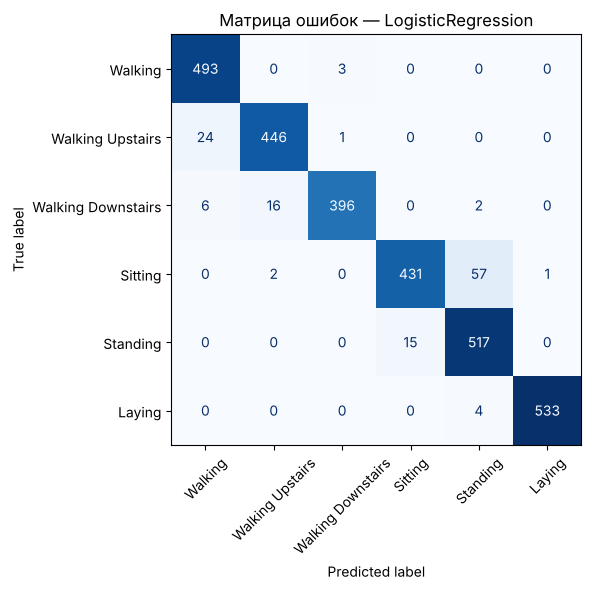

In [9]:
# Confusion matrix: rows = true class, columns = predicted class.
# Diagonal = correct answers; off-diagonal = which classes the model confuses.
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix(test_y, yhat), display_labels=target_names).plot(
    ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False)
ax.set_title('Матрица ошибок — LogisticRegression')
plt.tight_layout(); plt.show()

Основная часть ошибок приходится на пару **Sitting ↔ Standing**: обе позы статичны, и сигналы акселерометра/гироскопа у них очень похожи. Динамические классы (ходьба) и Laying распознаются почти идеально.

## Сравнение нескольких моделей с разными гиперпараметрами

Обучим набор моделей с различными значениями гиперпараметров и сравним их по `accuracy` и `macro F1` на тестовой выборке.

In [10]:
# Set of experiments: for each model we try several values of its key hyperparameter
# to see the transition from underfitting to overfitting
experiments = {
    # logistic regression: regularization strength C (smaller C -> stronger regularization)
    'LogReg C=0.01':  make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=2000)),
    'LogReg C=1':     make_pipeline(StandardScaler(), LogisticRegression(C=1,    max_iter=2000)),
    'LogReg C=100':   make_pipeline(StandardScaler(), LogisticRegression(C=100,  max_iter=5000)),
    # SVM: kernel type (linear / RBF), penalty C and RBF kernel width gamma
    'SVC linear C=1':   SVC(kernel='linear', C=1),
    'SVC rbf C=1':      SVC(kernel='rbf', C=1, gamma='scale'),   # gamma='scale' = 1 / (n_features * X.var())
    'SVC rbf C=100':    SVC(kernel='rbf', C=100, gamma='scale'),
    'SVC rbf gamma=1':  SVC(kernel='rbf', C=1, gamma=1),         # deliberately too large gamma
    # kNN: number of neighbors that vote
    'kNN k=1':   KNeighborsClassifier(n_neighbors=1,  n_jobs=-1),
    'kNN k=5':   KNeighborsClassifier(n_neighbors=5,  n_jobs=-1),
    'kNN k=25':  KNeighborsClassifier(n_neighbors=25, n_jobs=-1),
    # decision tree: maximum depth (None = unlimited)
    'Tree depth=3':    DecisionTreeClassifier(max_depth=3,    random_state=RANDOM_STATE),
    'Tree depth=10':   DecisionTreeClassifier(max_depth=10,   random_state=RANDOM_STATE),
    'Tree depth=None': DecisionTreeClassifier(max_depth=None, random_state=RANDOM_STATE),
    # random forest: number of trees in the ensemble (n_jobs=-1 = use all CPU cores)
    'RF n=10':   RandomForestClassifier(n_estimators=10,  random_state=RANDOM_STATE, n_jobs=-1),
    'RF n=100':  RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    'RF n=300':  RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
}

rows, predictions = [], {}  # rows = rows of the results table, predictions = predictions of each model
for name, clf in experiments.items():
    t0 = time.time()
    clf.fit(train_X, train_y)          # training
    fit_time = time.time() - t0
    pred = clf.predict(test_X)         # prediction on the test set
    predictions[name] = pred
    rows.append({'Модель': name,
                 'Семейство': name.split()[0],                         # used to color the plots
                 'Accuracy': accuracy_score(test_y, pred),             # share of correct answers
                 'Macro F1': f1_score(test_y, pred, average='macro'),  # mean F1 over classes
                 'Train acc': accuracy_score(train_y, clf.predict(train_X)),  # to diagnose overfitting
                 'Время обучения, c': fit_time})
    print(f'{name:18s}  acc={rows[-1]["Accuracy"]:.4f}  f1={rows[-1]["Macro F1"]:.4f}  ({fit_time:.1f} c)')

results = pd.DataFrame(rows).set_index('Модель')

LogReg C=0.01       acc=0.9447  f1=0.9448  (3.2 c)


LogReg C=1          acc=0.9555  f1=0.9554  (3.9 c)


LogReg C=100        acc=0.9457  f1=0.9446  (5.4 c)


SVC linear C=1      acc=0.9640  f1=0.9642  (0.7 c)


SVC rbf C=1         acc=0.9505  f1=0.9499  (1.4 c)


SVC rbf C=100       acc=0.9654  f1=0.9650  (0.8 c)


... (6 outputs left out)

Tree depth=None     acc=0.8622  f1=0.8595  (3.8 c)


RF n=10             acc=0.9053  f1=0.9029  (0.5 c)


RF n=100            acc=0.9257  f1=0.9241  (4.9 c)


RF n=300            acc=0.9287  f1=0.9271  (14.4 c)


In [11]:
#Результаты сравнения
# Table of all experiments sorted by accuracy; darker green = better
results.sort_values('Accuracy', ascending=False).style.format(
    {'Accuracy': '{:.4f}', 'Macro F1': '{:.4f}', 'Train acc': '{:.4f}', 'Время обучения, c': '{:.1f}'}
).background_gradient(subset=['Accuracy', 'Macro F1'], cmap='Greens')

,Семейство,Accuracy,Macro F1,Train acc,"Время обучения, c"
Модель,,,,,
SVC rbf C=100,SVC,0.9654,0.9650,0.9993,0.8
SVC linear C=1,SVC,0.9640,0.9642,0.9939,0.7
LogReg C=1,LogReg,0.9555,0.9554,0.9965,3.9
SVC rbf C=1,SVC,0.9505,0.9499,0.9791,1.4
LogReg C=100,LogReg,0.9457,0.9446,0.9999,5.4
LogReg C=0.01,LogReg,0.9447,0.9448,0.9831,3.2
RF n=300,RF,0.9287,0.9271,1.0000,14.4
RF n=100,RF,0.9257,0.9241,1.0000,4.9
RF n=10,RF,0.9053,0.9029,0.9996,0.5


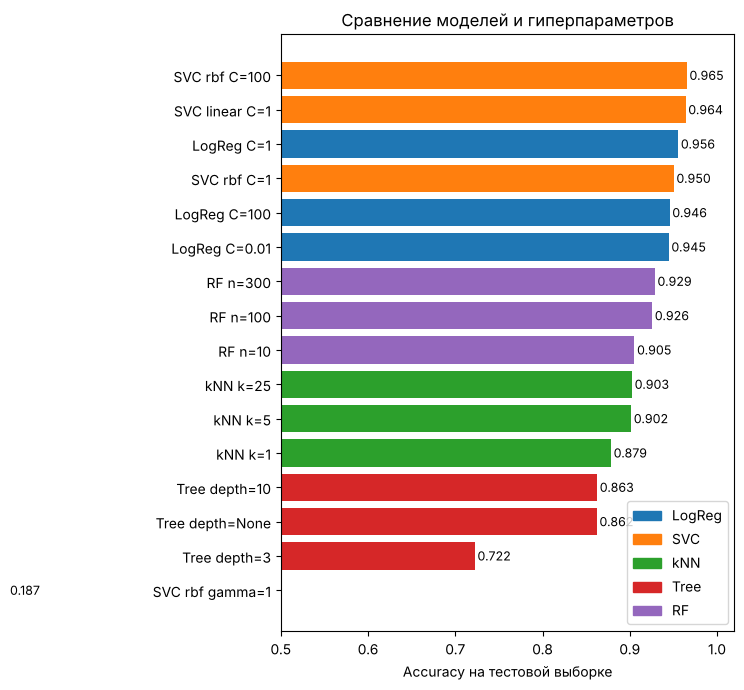

In [12]:
# Horizontal bar chart of test accuracy; bar color = model family
palette = dict(zip(results['Семейство'].unique(), sns.color_palette('tab10')))
r = results.sort_values('Accuracy')
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(r.index, r['Accuracy'], color=[palette[f] for f in r['Семейство']])
for i, v in enumerate(r['Accuracy']):          # label each bar with its value
    ax.text(v + 0.003, i, f'{v:.3f}', va='center', fontsize=9)
ax.set_xlim(0.5, 1.02)   # SVC gamma=1 (0.19) is beyond the left limit; it is shown in the table above
ax.set_xlabel('Accuracy на тестовой выборке')
ax.set_title('Сравнение моделей и гиперпараметров')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()],
          labels=list(palette.keys()), loc='lower right')
plt.tight_layout(); plt.show()

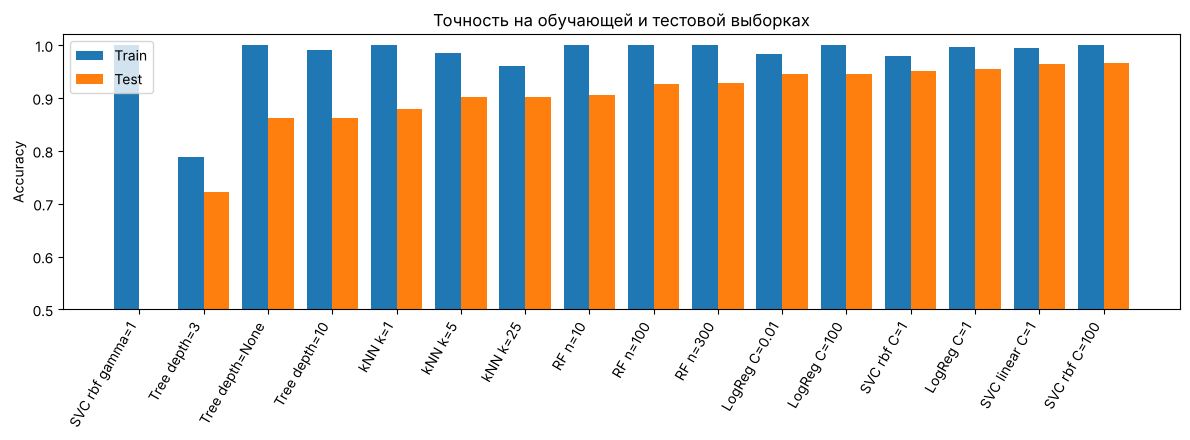

In [13]:
# Train vs test accuracy.
# A large gap train >> test indicates overfitting (unlimited-depth tree, kNN k=1, SVC gamma=1)
r = results.sort_values('Accuracy')
x = np.arange(len(r))
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(x - 0.2, r['Train acc'], 0.4, label='Train')
ax.bar(x + 0.2, r['Accuracy'], 0.4, label='Test')
ax.set_xticks(x); ax.set_xticklabels(r.index, rotation=60, ha='right')
ax.set_ylim(0.5, 1.02); ax.set_ylabel('Accuracy'); ax.legend()
ax.set_title('Точность на обучающей и тестовой выборках')
plt.tight_layout(); plt.show()

### Влияние отдельных гиперпараметров (кривые валидации на тесте)

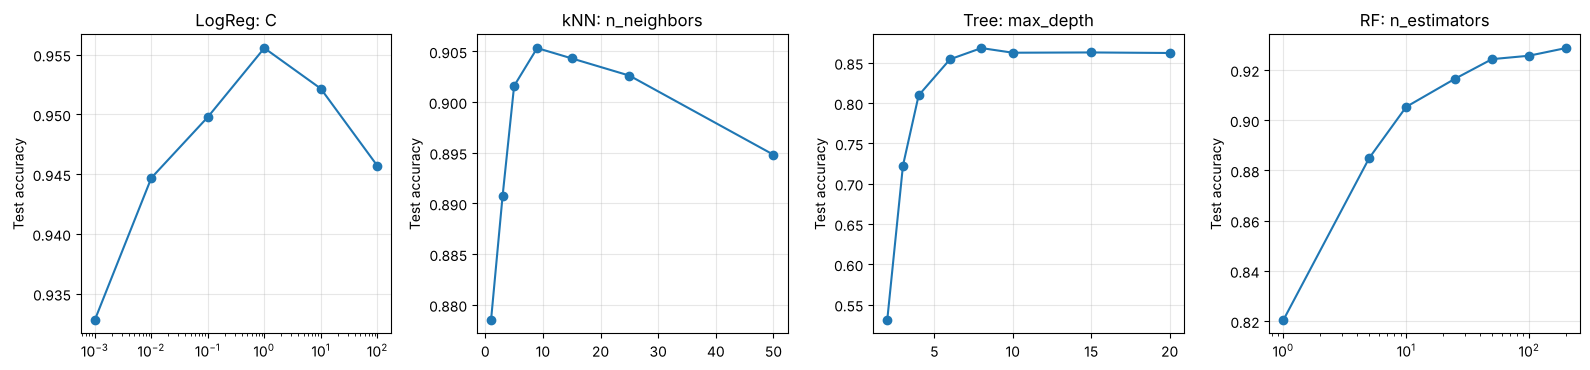

In [14]:
# Validation curves: vary one hyperparameter while keeping the others fixed
# and see how test quality changes. curves[name] = (values, accuracy, x-axis scale)
curves = {}

# Logistic regression: C on a logarithmic grid
Cs = [0.001, 0.01, 0.1, 1, 10, 100]
curves['LogReg: C'] = (Cs, [accuracy_score(test_y, make_pipeline(StandardScaler(),
                        LogisticRegression(C=c, max_iter=5000)).fit(train_X, train_y).predict(test_X)) for c in Cs], 'log')

# kNN: number of neighbors
ks = [1, 3, 5, 9, 15, 25, 50]
curves['kNN: n_neighbors'] = (ks, [accuracy_score(test_y, KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
                        .fit(train_X, train_y).predict(test_X)) for k in ks], 'linear')

# Decision tree: depth
ds = [2, 3, 4, 6, 8, 10, 15, 20]
curves['Tree: max_depth'] = (ds, [accuracy_score(test_y, DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
                        .fit(train_X, train_y).predict(test_X)) for d in ds], 'linear')

# Random forest: number of trees
ns = [1, 5, 10, 25, 50, 100, 200]
curves['RF: n_estimators'] = (ns, [accuracy_score(test_y, RandomForestClassifier(n_estimators=n, random_state=RANDOM_STATE, n_jobs=-1)
                        .fit(train_X, train_y).predict(test_X)) for n in ns], 'log')

# Draw 4 plots in one row
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (title, (xs, ys, scale)) in zip(axes, curves.items()):
    ax.plot(xs, ys, marker='o')
    ax.set_xscale(scale); ax.set_title(title); ax.set_ylabel('Test accuracy'); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

Лучшая модель: SVC rbf C=100
                    precision    recall  f1-score   support

           Walking     0.9607    0.9859    0.9731       496
  Walking Upstairs     0.9498    0.9639    0.9568       471
Walking Downstairs     0.9900    0.9476    0.9684       420
           Sitting     0.9823    0.9022    0.9406       491
          Standing     0.9193    0.9850    0.9510       532
            Laying     1.0000    1.0000    1.0000       537

          accuracy                         0.9654      2947
         macro avg     0.9670    0.9641    0.9650      2947
      weighted avg     0.9664    0.9654    0.9653      2947



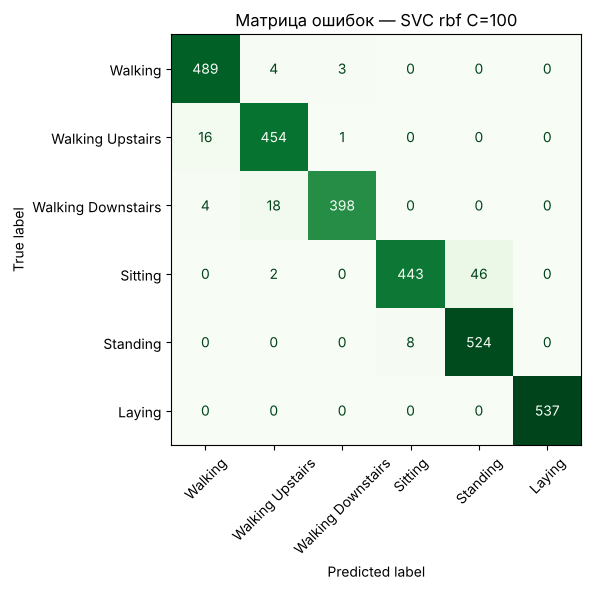

In [15]:
# Detailed analysis of the best model: per-class report and confusion matrix
best_name = results['Accuracy'].idxmax()
print('Лучшая модель:', best_name)
print(classification_report(test_y, predictions[best_name], target_names=target_names, digits=4))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix(test_y, predictions[best_name]), display_labels=target_names).plot(
    ax=ax, cmap='Greens', xticks_rotation=45, colorbar=False)
ax.set_title(f'Матрица ошибок — {best_name}')
plt.tight_layout(); plt.show()

## Задание


Выведите отчет о классификации, сравнив предсказания (`yhat`) с базовой истиной (`test_y`).

В чем разница между показателями `precision` и `recall`? Что такое показатель `F1`?

Используйте вариации нескольких моделей с разными гиперпараметрами. Сравните полученный результат (визуализируйте полученный результат).

Что такое гиперпараметры модели машинного обучения (МО)?

Опишите влияние гиперпараметров в выбранных вами моделях МО.

## Ответы на вопросы

### Разница между `precision` и `recall`. Что такое `F1`?

Для класса *k* обозначим: **TP** — объекты класса *k*, верно отнесённые к *k*; **FP** — объекты других классов, ошибочно отнесённые к *k*; **FN** — объекты класса *k*, ошибочно отнесённые к другим классам.

* **Precision (точность)** = TP / (TP + FP) — какая доля объектов, которые модель назвала классом *k*, действительно к нему относится. Отвечает на вопрос «насколько можно доверять положительному ответу модели».
* **Recall (полнота)** = TP / (TP + FN) — какую долю всех объектов класса *k* модель нашла. Отвечает на вопрос «сколько объектов класса модель пропустила».
* **F1-мера** = 2 · Precision · Recall / (Precision + Recall) — гармоническое среднее точности и полноты. Она высока, только если обе метрики высоки одновременно, поэтому удобна как единый показатель качества.

Пример из отчёта логистической регрессии: у класса *Standing* recall = 0.97, но precision = 0.89 — модель почти не пропускает стоящих людей, но часто записывает в *Standing* сидящих. У *Sitting*, наоборот, precision 0.97 при recall 0.88. Это та же путаница Sitting ↔ Standing, видная на матрице ошибок.

`macro avg` — простое среднее метрик по классам (все классы равноправны), `weighted avg` — среднее, взвешенное по числу объектов класса (`support`).

### Что такое гиперпараметры модели МО?

**Гиперпараметры** — это параметры, которые задаются **до** обучения и не подбираются алгоритмом обучения из данных: сила регуляризации `C`, тип ядра SVM, число соседей `k`, глубина дерева, число деревьев в лесу и т.д. Ими они отличаются от **параметров** модели (веса логистической регрессии, опорные векторы SVM, пороги разбиений в дереве), которые находятся в процессе `fit`.

Гиперпараметры управляют сложностью модели и, тем самым, балансом смещения и разброса (bias–variance): слишком простая модель недообучается, слишком сложная — переобучается. Их подбирают перебором (Grid/Random Search, байесовская оптимизация) по качеству на валидационной выборке или кросс-валидации. В данной работе для наглядности сравнение проводилось на тестовой выборке; в реальной задаче подбор надо делать на валидации (например, `GridSearchCV` с разбиением по `subject`), а тест использовать только для финальной оценки.

### Влияние гиперпараметров в выбранных моделях

| Модель | Гиперпараметр | Наблюдение |
|---|---|---|
| LogisticRegression | `C` | Кривая с максимумом: при `C=0.001` accuracy ≈ 0.933 (сильная регуляризация, недообучение), оптимум при `C=1` ≈ 0.956, при `C=100` падает до ≈ 0.946 (слабая регуляризация, переобучение — train acc ≈ 1.0). |
| SVC | `kernel`, `C`, `gamma` | Линейное ядро уже даёт 0.964, т.е. данные почти линейно разделимы. RBF с `C=1` — 0.951, увеличение `C` до 100 (меньше регуляризации) поднимает качество до **0.965 — лучший результат**. `gamma=1` при 561 признаке делает ядро слишком «узким»: каждый объект похож только на себя, модель запоминает обучающую выборку (train ≈ 1.0) и полностью разваливается на тесте (0.19). Это наглядный пример катастрофического переобучения из-за одного гиперпараметра. |
| kNN | `n_neighbors` | При `k=1` accuracy 0.879 (высокий разброс, чувствительность к шуму). Рост `k` сглаживает решение, максимум ≈ 0.905 при `k≈9`, дальше (k=50) качество снова падает — соседи из других классов начинают «перевешивать». |
| DecisionTree | `max_depth` | Глубина 2–3 — сильное недообучение (0.53–0.72). Качество растёт до глубины ≈ 8 (0.87), после чего выходит на плато: дерево без ограничения глубины идеально выучивает train (1.0), но на тесте лучше не становится — переобучение. |
| RandomForest | `n_estimators` | Одно дерево — 0.82, 10 деревьев — 0.905, 100 — 0.926, 300 — 0.929. Увеличение числа деревьев уменьшает разброс ансамбля и монотонно улучшает качество, но с убывающей отдачей, тогда как время обучения растёт линейно. Переобучения с ростом `n_estimators` не возникает. |

### Выводы

* Лучшие результаты показали **SVM** (RBF, `C=100`: accuracy 0.965, macro F1 0.965; линейный: 0.964) и **логистическая регрессия** (`C=1`: 0.956). Признаки уже хорошо сконструированы, поэтому простые линейные модели работают отлично и быстро.
* Ансамбль деревьев (RandomForest, ≈0.93) заметно лучше одиночного дерева (≈0.86), но уступает линейным моделям; kNN (≈0.90) страдает от высокой размерности пространства.
* Во всех моделях основная ошибка — путаница **Sitting ↔ Standing**; класс **Laying** и динамические активности распознаются почти идеально.
* Неудачный выбор гиперпараметра может обрушить даже сильную модель (SVC с `gamma=1` — 0.19), поэтому подбор гиперпараметров — обязательный этап построения модели.
